### Signal Or Noise

A small learning project: should an event count as signal, or noise?

Radiation detectors produce many events, some from the object of interest and some
from background. A common approach is a single hand-tuned threshold. This project
compares that rule with a machine-learning classifier, and shows how the choice
changes the resulting image.

Steps:
1. Loads real neutron/gamma detector pulses (public Zenodo dataset).
2. Builds a classic one-feature rule (tail-to-total ratio) and traces its ROC trade-off.
3. Trains a multi-feature ML model and compares it with the rule, also under added noise.
4. Builds a *synthetic* 2D scene (a toy, not real physics) to show how event selection
   affects a heat map.
5. Wraps everything in a Streamlit app with a threshold slider and a noise slider.

Data:
Liu et al., "Pulse Shape Discrimination Algorithms: A Survey and Benchmark",
Zenodo, doi:10.5281/zenodo.16730902 (EJ299-33 scintillator, AmBe source).
Check the record for the license before redistributing any data.

In [1]:
# Loads the dataset
!wget -q -O Datasets.zip "https://zenodo.org/records/16730902/files/Datasets.zip?download=1"
!unzip -q -o Datasets.zip -d data_raw

In [2]:
import pandas as pd
AmBe_G_train=pd.read_csv('/content/data_raw/AmBe/Train/EJ299_33_AmBe_9414_gamma_train.txt',sep=r"\s+",header=None, comment='#')
AmBe_G_test=pd.read_csv('/content/data_raw/AmBe/Test/EJ299_33_AmBe_9414_gamma_test.txt',sep=r"\s+",header=None, comment='#')
AmBe_N_train=pd.read_csv('/content/data_raw/AmBe/Train/EJ299_33_AmBe_9414_neutron_train.txt',sep=r"\s+",header=None, comment='#')
AmBe_N_test=pd.read_csv('/content/data_raw/AmBe/Test/EJ299_33_AmBe_9414_neutron_test.txt',sep=r"\s+",header=None, comment='#')

In [3]:
AmBe_G_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2201 entries, 0 to 2200
Columns: 280 entries, 0 to 279
dtypes: float64(280)
memory usage: 4.7 MB


In [4]:
AmBe_N_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 623 entries, 0 to 622
Columns: 280 entries, 0 to 279
dtypes: float64(280)
memory usage: 1.3 MB


In [5]:
AmBe_G_train.describe()

,0,1,2,3,4,5,6,7,8,9,...,270,271,272,273,274,275,276,277,278,279
count,2201.000000,2201.000000,2201.000000,2201.000000,2201.000000,2201.000000,2201.000000,2201.000000,2201.000000,2201.000000,...,2201.000000,2201.000000,2201.000000,2201.000000,2201.000000,2201.000000,2201.000000,2201.000000,2201.000000,2201.000000
mean,0.012673,0.012572,0.012713,0.012761,0.012761,0.012789,0.012646,0.012546,0.012600,0.012610,...,0.029217,0.030985,0.032228,0.033085,0.033025,0.032025,0.031154,0.029593,0.028289,0.026918
std,0.006036,0.006118,0.006030,0.006050,0.005875,0.005998,0.005935,0.006094,0.006013,0.005868,...,0.007469,0.007420,0.007381,0.007275,0.007114,0.007057,0.007018,0.007285,0.007151,0.007031
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.005464,0.005988,0.011050,0.011300,0.010989,0.010989,0.010929,0.005747,0.005495,0.005747
25%,0.010870,0.006135,0.006173,0.010870,0.010929,0.010929,0.006211,0.006135,0.010870,0.010870,...,0.023811,0.027324,0.028091,0.028573,0.028573,0.027934,0.027625,0.023811,0.023256,0.022472
50%,0.011834,0.011834,0.011834,0.011905,0.011905,0.011905,0.011905,0.011834,0.011834,0.011834,...,0.029071,0.030121,0.031057,0.033150,0.033150,0.030676,0.030121,0.029241,0.028573,0.027779
75%,0.017241,0.017341,0.017341,0.017341,0.017241,0.017341,0.017341,0.017241,0.017341,0.017241,...,0.034286,0.035504,0.036364,0.036810,0.036810,0.036145,0.035504,0.034483,0.033520,0.030676
max,0.036586,0.051723,0.034885,0.041667,0.034483,0.035714,0.036586,0.033709,0.033520,0.032788,...,0.057471,0.068182,0.068182,0.068182,0.061111,0.059879,0.061111,0.058479,0.055215,0.049080


In [6]:
AmBe_N_train.sample(1)

,0,1,2,3,4,5,6,7,8,9,...,270,271,272,273,274,275,276,277,278,279
555,0.005556,0.0,0.011111,0.005556,0.005556,0.005556,0.011111,0.011111,0.005556,0.005556,...,0.049999,0.055556,0.049999,0.038889,0.044444,0.033334,0.038889,0.038889,0.022223,0.033334


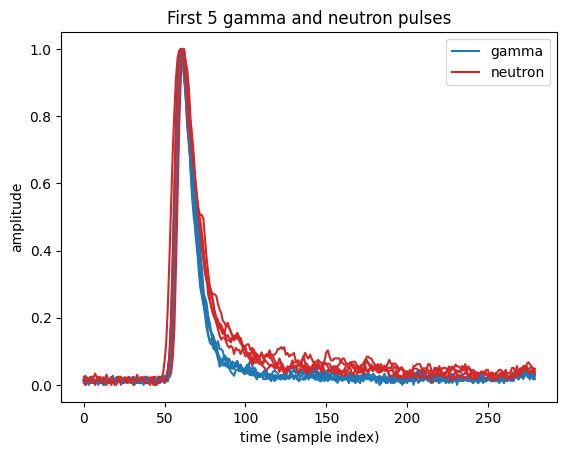

In [7]:
import matplotlib.pyplot as plt

dfG = AmBe_G_train
dfN = AmBe_N_train


for i in range(5):        # plot the first 5 events
    plt.plot(dfG.iloc[i].values, color="tab:blue", label="gamma" if i == 0 else None)
    plt.plot(dfN.iloc[i].values, color="tab:red", label="neutron" if i == 0 else None)

plt.xlabel("time (sample index)")
plt.ylabel("amplitude")
plt.title("First 5 gamma and neutron pulses")
plt.legend()
plt.show()

In [8]:
dfG_ratio=dfG.iloc[:, 80:].sum(axis=1)/dfG.sum(axis=1)
dfN_ratio=dfN.iloc[:, 80:].sum(axis=1)/dfN.sum(axis=1)
print(len(dfG_ratio))
print(len(dfN_ratio))
print(dfG_ratio.std())
print(dfN_ratio.std())
print(dfG_ratio.mean())
print(dfN_ratio.mean())

2201
623
0.022538468439295797
0.025251413774384703
0.280118686972694
0.41399663434162337


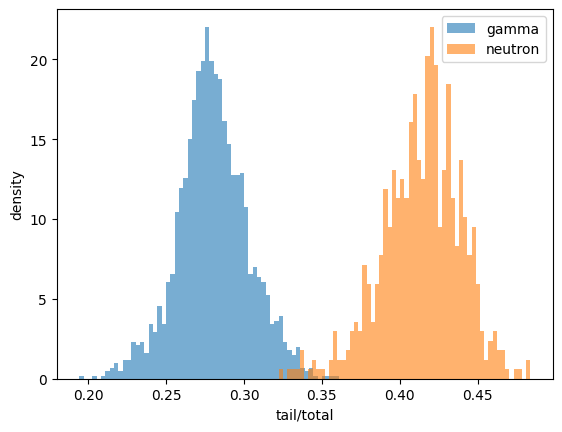

In [9]:
plt.hist(dfG_ratio, bins=60, density=True, alpha=0.6, label='gamma')
plt.hist(dfN_ratio, bins=60, density=True, alpha=0.6, label='neutron')
plt.xlabel('tail/total')
plt.ylabel('density')
plt.legend()
plt.show()

In [10]:
thr=(dfG_ratio.mean() + dfN_ratio.mean())/2
print(thr)
G_mist=dfG_ratio[dfG_ratio>thr].count()
N_mist=dfN_ratio[dfN_ratio<thr].count()
print(G_mist)
print(N_mist)
error_rate=(G_mist+N_mist)/(len(dfG_ratio)+len(dfN_ratio))
accuracy=1-error_rate
print(accuracy)

0.3470576606571587
4
10
0.9950424929178471


In [11]:
AmBe_G_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5136 entries, 0 to 5135
Columns: 280 entries, 0 to 279
dtypes: float64(280)
memory usage: 11.0 MB


In [12]:
AmBe_N_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1454 entries, 0 to 1453
Columns: 280 entries, 0 to 279
dtypes: float64(280)
memory usage: 3.1 MB


In [13]:
dfGt = AmBe_G_test
dfNt = AmBe_N_test

dfGt_ratio=dfGt.iloc[:, 80:].sum(axis=1)/dfGt.sum(axis=1)
dfNt_ratio=dfNt.iloc[:, 80:].sum(axis=1)/dfNt.sum(axis=1)
print(len(dfGt_ratio))
print(len(dfNt_ratio))
print(dfGt_ratio.std())
print(dfNt_ratio.std())
print(dfGt_ratio.mean())
print(dfNt_ratio.mean())

5136
1454
0.02302554036092712
0.025536080952629287
0.28107811563615676
0.41387906393972473


In [14]:
thr=(dfG_ratio.mean() + dfN_ratio.mean())/2
print(thr)
Gt_mist=dfGt_ratio[dfGt_ratio>thr].count()
Nt_mist=dfNt_ratio[dfNt_ratio<thr].count()
print(Gt_mist)
print(Nt_mist)
error_rate=(Gt_mist+Nt_mist)/(len(dfGt_ratio)+len(dfNt_ratio))
accuracy=1-error_rate
print(accuracy)

0.3470576606571587
9
12
0.9968133535660091


In [15]:
TPR=dfNt_ratio[dfNt_ratio>thr].count()/len(dfNt_ratio)
FPR=dfGt_ratio[dfGt_ratio>thr].count()/len(dfGt_ratio)
print(TPR)
print(FPR)

0.9917469050894085
0.0017523364485981308


In [16]:
def rates(t):
  TPR=dfNt_ratio[dfNt_ratio>t].count()/len(dfNt_ratio)
  FPR=dfGt_ratio[dfGt_ratio>t].count()/len(dfGt_ratio)
  return TPR, FPR


In [17]:
rates(0.35)

(np.float64(0.9903713892709766), np.float64(0.0011682242990654205))

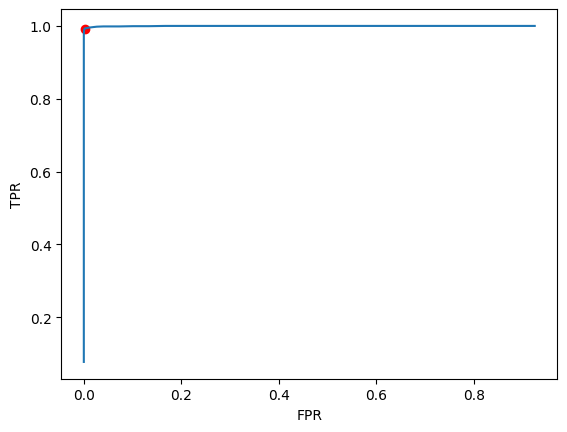

In [18]:
import numpy as np
thresholds = np.linspace(0.25, 0.45, 50)
roc = pd.DataFrame([rates(t) for t in thresholds], columns=["TPR", "FPR"])
TPR_thr, FPR_thr = rates(thr)
plt.plot(roc["FPR"], roc["TPR"])
plt.scatter(FPR_thr, TPR_thr, color="red")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.show()

In [19]:
sigma = 0.05
dfGt_noisy=dfGt+np.random.normal(0, sigma, size=dfGt.shape)
dfNt_noisy=dfNt+np.random.normal(0, sigma, size=dfNt.shape)
dfGt_noisy.shape

(5136, 280)

In [20]:
dfGt_noisy_ratio=dfGt_noisy.iloc[:, 80:].sum(axis=1)/dfGt_noisy.sum(axis=1)
dfNt_noisy_ratio=dfNt_noisy.iloc[:, 80:].sum(axis=1)/dfNt_noisy.sum(axis=1)
G_N_mist=dfGt_noisy_ratio[dfGt_noisy_ratio>thr].count()
N_N_mist=dfNt_noisy_ratio[dfNt_noisy_ratio<thr].count()
print(G_N_mist)
print(N_N_mist)
error_rate=(G_N_mist+N_N_mist)/(len(dfGt_noisy_ratio)+len(dfNt_noisy_ratio))
accuracy=1-error_rate
print(accuracy)

144
25
0.9743550834597876


In [21]:
print(thr)
print(dfGt.shape, dfNt.shape)


0.3470576606571587
(5136, 280) (1454, 280)


In [22]:
def accuracy_at(sigma):
  dfGt_noisy=dfGt+np.random.normal(0, sigma, size=dfGt.shape)
  dfNt_noisy=dfNt+np.random.normal(0, sigma, size=dfNt.shape)
  dfGt_noisy_ratio=dfGt_noisy.iloc[:, 80:].sum(axis=1)/dfGt_noisy.sum(axis=1)
  dfNt_noisy_ratio=dfNt_noisy.iloc[:, 80:].sum(axis=1)/dfNt_noisy.sum(axis=1)
  G_N_mist=dfGt_noisy_ratio[dfGt_noisy_ratio>thr].count()
  N_N_mist=dfNt_noisy_ratio[dfNt_noisy_ratio<thr].count()
  error_rate=(G_N_mist+N_N_mist)/(len(dfGt_noisy_ratio)+len(dfNt_noisy_ratio))
  accuracy=1-error_rate
  return accuracy


In [23]:
accuracy_at(0.05)

np.float64(0.9781487101669196)

In [24]:
sigmas = [0, 0.02, 0.05, 0.1, 0.2]
accs = pd.DataFrame([accuracy_at(sigma) for sigma in sigmas])
print(accs)

          0
0  0.996813
1  0.994992
2  0.976935
3  0.900607
4  0.759484


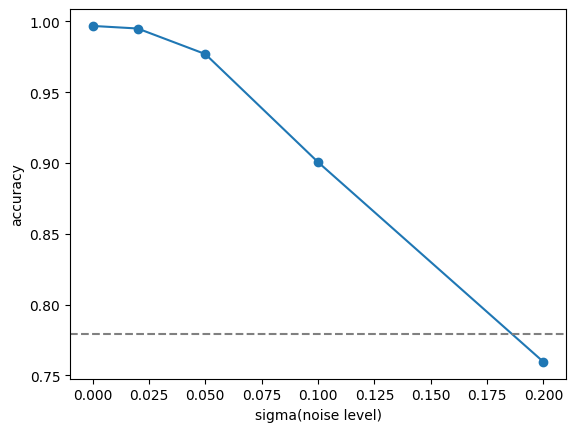

In [25]:
plt.plot(sigmas, accs, marker="o")
plt.axhline(0.779, color="gray", linestyle="--")
plt.xlabel("sigma(noise level)")
plt.ylabel("accuracy")
plt.show()

In [26]:
x_train=pd.concat([dfG, dfN],ignore_index=True)
y_train=np.concatenate([np.zeros(len(dfG)), np.ones(len(dfN))])
x_test=pd.concat([dfGt, dfNt],ignore_index=True)
y_test=np.concatenate([np.zeros(len(dfGt)), np.ones(len(dfNt))])

In [27]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=2000)
model.fit(x_train, y_train)
model.score(x_test, y_test)
model.score(x_train, y_train)

0.9953966005665722

In [28]:
model.score(x_test, y_test)

0.9954476479514416

In [29]:
sigma = 0.2
x_test_noisy=x_test+np.random.normal(0, sigma, size=x_test.shape)
model.score(x_test_noisy, y_test)

0.9239757207890743

In [30]:
sigmas = [0, 0.02, 0.05, 0.1, 0.2]
def accuracy_ML(sigma):
  x_test_noisy=x_test+np.random.normal(0, sigma, size=x_test.shape)
  model.score(x_test_noisy, y_test)
  return model.score(x_test_noisy, y_test)

In [31]:
accs_ml = [accuracy_ML(sigma) for sigma in sigmas]
print(accs_ml)

[0.9954476479514416, 0.9945371775417299, 0.9940819423368741, 0.9848254931714719, 0.9125948406676783]


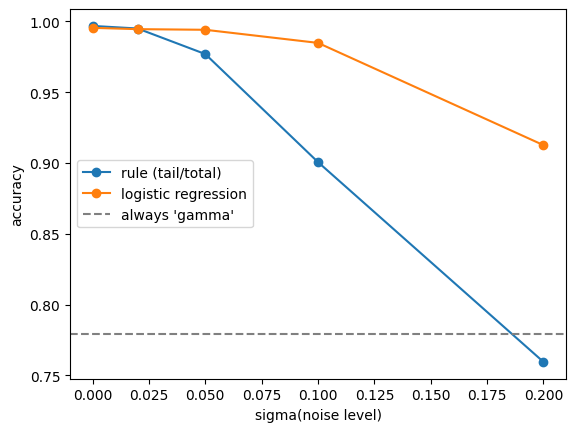

In [32]:
plt.plot(sigmas, accs[0], marker="o", label="rule (tail/total)")
plt.plot(sigmas, accs_ml, marker="o", label="logistic regression")
plt.axhline(0.779, color="gray", linestyle="--", label="always 'gamma'")
plt.xlabel("sigma(noise level)")
plt.ylabel("accuracy")
plt.legend()
plt.show()

In [36]:
import pickle
pickle.dump({"model": model, "thr": float(thr)}, open("model.pkl", "wb"))